# Feature Engineering và lựa chọn đặc trưng

Phần này xây dựng và đánh giá đặc trưng đầu vào cho bài toán dự đoán nồng độ CO và NOx từ dữ liệu vận hành tuabin khí, gồm: phân tích đa cộng tuyến giữa 9 đặc trưng gốc, đề xuất đặc trưng mới có cơ sở vật lý, lựa chọn tập đặc trưng cho từng nhóm mô hình, đánh giá mức độ quan trọng, đối chiếu với cơ chế cháy và phân tích nguyên nhân sai số NOx trên tập kiểm tra.

**Tóm tắt kết quả**

- TEY, CDP và GTEP gần như mang cùng một thông tin (VIF từ 262 đến 442); loại bỏ chúng không làm giảm độ chính xác.
- Hai đặc trưng mới được giữ lại là độ ẩm tuyệt đối `AH_abs` và tỉ số `CDP_GTEP_ratio`, giúp mô hình tuyến tính giảm RMSE khoảng 3% với CO và 6.5% với NOx.
- CO phụ thuộc chủ yếu vào TIT; NOx phụ thuộc chủ yếu vào độ ẩm tuyệt đối.
- Sai số lớn của NOx trên tập kiểm tra đến từ concept drift bắt đầu năm 2014, không đến từ tập đặc trưng.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

BASE_DIR = Path().resolve().parent if Path().resolve().name == 'notebooks' else Path().resolve()
sys.path.append(str(BASE_DIR))

from src.data_prep import load_and_clean_data
from src.feature_eng import (
    BASE_FEATURES, TARGETS, CANDIDATE_FEATURES, ENGINEERED_FEATURES,
    FS_BASE, FS_COMPACT, FS_ENGINEERED,
    add_physical_features, compute_vif, prune_by_vif, time_cv_rmse,
    group_permutation_importance, scale_features,
)

BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#a8a8a3'
DIVERGING = LinearSegmentedColormap.from_list('div', [ORANGE, '#f4f4f2', BLUE])
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e5e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})
LABEL = {'CO_clipped': 'CO', 'NOX': 'NOx'}

FIG_DIR = BASE_DIR / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'numpy {np.__version__}, pandas {pd.__version__}, scikit-learn {sklearn.__version__}')

numpy 2.5.3, pandas 3.0.5, scikit-learn 1.9.1


## 1. Dữ liệu và phương pháp đánh giá

Dữ liệu được nạp và làm sạch bằng `src/data_prep.py`: loại dòng trùng lặp và cắt CO ở phân vị 99 thành `CO_clipped`. Tập huấn luyện gồm các năm 2011–2013, tập kiểm tra gồm 2014–2015.

Để tránh rò rỉ dữ liệu, mọi quyết định về đặc trưng chỉ dựa trên tập huấn luyện. Các phương án được so sánh bằng kiểm định chéo theo thời gian bên trong tập huấn luyện: huấn luyện trên các năm trước và đánh giá trên năm kế tiếp (hai fold: 2011 → 2012 và 2011–2012 → 2013), sai số là RMSE trung bình của hai fold. Cột `year` không được dùng làm đặc trưng vì các năm của tập kiểm tra không xuất hiện trong quá trình huấn luyện.

In [2]:
df = load_and_clean_data(BASE_DIR / 'data' / 'raw' / 'gas_turbine_data.csv')
train = df[df['year'] <= 2013].reset_index(drop=True)
test = df[df['year'] >= 2014].reset_index(drop=True)
YEARS = [2011, 2012, 2013]

print(f'Train: {train.shape[0]} dòng ({YEARS[0]} đến {YEARS[-1]})')
print(f'Test : {test.shape[0]} dòng (2014 đến 2015)')

Train: 22191 dòng (2011 đến 2013)
Test : 14535 dòng (2014 đến 2015)


## 2. Đa cộng tuyến giữa các đặc trưng gốc

Đa cộng tuyến làm hệ số của mô hình tuyến tính kém ổn định và khiến mức độ quan trọng bị chia sẻ giữa các đặc trưng tương tự nhau. Mức độ đa cộng tuyến được đo bằng ma trận tương quan và hệ số phóng đại phương sai (VIF):

$$\mathrm{VIF}_j = \frac{1}{1 - R_j^2}$$

trong đó $R_j^2$ là hệ số xác định khi hồi quy đặc trưng $j$ theo các đặc trưng còn lại. VIF lớn hơn 10 được xem là đa cộng tuyến nghiêm trọng.

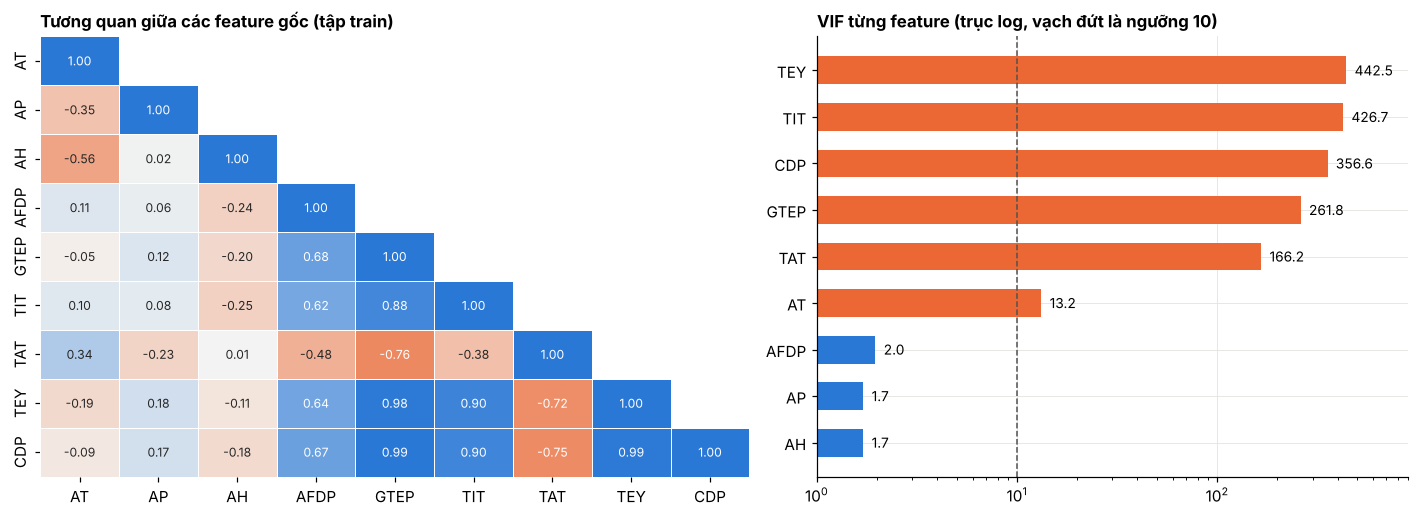

In [3]:
corr = train[BASE_FEATURES].corr()
vif_base = compute_vif(train[BASE_FEATURES]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.2, 1]})

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 8}, linewidths=0.5, cbar=False, ax=axes[0])
axes[0].set_title('Tương quan giữa các feature gốc (tập train)')
axes[0].grid(False)

colors = [ORANGE if v > 10 else BLUE for v in vif_base]
axes[1].barh(vif_base.index, vif_base.values, color=colors, height=0.6)
axes[1].axvline(10, color='#52514e', lw=1, ls='--')
axes[1].set_xscale('log')
axes[1].set_xlim(1, 900)
for i, v in enumerate(vif_base):
    axes[1].text(v * 1.1, i, f'{v:.1f}', va='center', fontsize=9)
axes[1].set_title('VIF từng feature (trục log, vạch đứt là ngưỡng 10)')

plt.tight_layout()
plt.savefig(FIG_DIR / 'fe_01_multicollinearity.png', dpi=200, bbox_inches='tight')
plt.show()

**Nhận xét.** Sáu trên chín đặc trưng có VIF lớn hơn 10, cao nhất là TEY (442), TIT (427) và CDP (357). TEY, CDP và GTEP tương quan với nhau từ 0.98 đến 0.99 do cùng phản ánh tải của tuabin. TIT chỉ tương quan khoảng 0.9 với từng đặc trưng khác nhưng vẫn có VIF rất cao, cho thấy sự dư thừa đến từ tổ hợp của nhiều đặc trưng, điều mà ma trận tương quan từng cặp không phát hiện được.

## 3. Đề xuất đặc trưng mới

Sáu đặc trưng ứng viên được tính từ 9 cột gốc, không sử dụng dữ liệu bên ngoài:

| Đặc trưng | Công thức | Ý nghĩa |
|---|---|---|
| `TIT_TAT_diff` | TIT − TAT | Độ giảm nhiệt độ khí qua tuabin, phản ánh năng lượng chuyển thành công |
| `TEY_per_TIT` | TEY / TIT | Sản lượng điện trên mỗi đơn vị nhiệt độ đầu vào, thước đo hiệu suất thô |
| `CDP_AP_ratio` | CDP / AP | Tỉ số áp suất xả máy nén so với áp suất môi trường |
| `CDP_GTEP_ratio` | CDP / GTEP | Tách phần khác biệt giữa hai áp suất có tương quan 0.98 |
| `AH_abs` | xem bên dưới | Độ ẩm tuyệt đối (g/m³), tức lượng hơi nước thực tế trong không khí; hơi nước làm giảm nhiệt độ ngọn lửa nên ảnh hưởng đến NOx |
| `AT_x_AH` | AT × AH | Tương tác giữa nhiệt độ và độ ẩm cho mô hình tuyến tính |

Độ ẩm tương đối AH phụ thuộc nhiệt độ: cùng một giá trị AH có thể ứng với lượng hơi nước rất khác nhau. Độ ẩm tuyệt đối được tính từ AT (°C, ký hiệu $T$) và AH (%):

$$e_s = 6.112\,\exp\left(\frac{17.62\,T}{243.12 + T}\right), \qquad e = e_s\cdot\frac{AH}{100}, \qquad AH_{abs} = \frac{216.7\,e}{T + 273.15}$$

trong đó $e_s$ là áp suất hơi bão hoà theo công thức Magnus (hPa) và $e$ là áp suất hơi nước thực tế. Bảng dưới trình bày tương quan Spearman giữa các đặc trưng và hai target trên tập huấn luyện.

In [4]:
train_fe = add_physical_features(train)
cand_corr = train_fe[BASE_FEATURES + CANDIDATE_FEATURES + TARGETS].corr(method='spearman')
cand_corr.loc[BASE_FEATURES + CANDIDATE_FEATURES, TARGETS].rename(columns=LABEL).round(2)

,CO,NOx
AT,-0.04,-0.62
AP,-0.06,0.19
AH,0.22,0.13
AFDP,-0.48,-0.11
GTEP,-0.71,-0.12
TIT,-0.73,-0.14
TAT,0.22,-0.11
TEY,-0.70,0.05
CDP,-0.72,-0.10
TIT_TAT_diff,-0.73,-0.12


## 4. Đánh giá đặc trưng mới

`AH_abs` có tương quan với NOx (−0.69) mạnh hơn nhiều so với AH gốc (0.13). Tuy nhiên tương quan cao chưa chắc cải thiện dự đoán, nên mỗi ứng viên được đánh giá trực tiếp bằng cách thêm riêng lẻ vào 9 đặc trưng gốc. Hai mô hình khác họ được sử dụng: Ridge (α = 1, có chuẩn hoá) và Random Forest, cho cả hai target, tổng cộng 4 cấu hình.

Quy tắc giữ đặc trưng được cố định trước khi chạy thực nghiệm: RMSE giảm ít nhất 0.5% ở tối thiểu 2 trên 4 cấu hình và không cấu hình nào tăng quá 1%.

In [5]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
forest = RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=0)
MODELS = {'Ridge': ridge, 'Random Forest': forest}

def score_set(cols, models=MODELS):
    return {(LABEL[t], name): time_cv_rmse(model, train_fe, cols, t, YEARS)
            for t in TARGETS for name, model in models.items()}

sets = {'Gốc (9 feature)': BASE_FEATURES}
sets.update({f'+ {c}': BASE_FEATURES + [c] for c in CANDIDATE_FEATURES})

ablation = pd.DataFrame({name: score_set(cols) for name, cols in sets.items()}).T
ablation.columns = pd.MultiIndex.from_tuples(ablation.columns)
ablation.round(3)

CO                  NOx              
                  Ridge Random Forest  Ridge Random Forest
Gốc (9 feature)   1.359         1.212  9.103         6.480
+ TIT_TAT_diff    1.359         1.209  9.110         6.478
+ TEY_per_TIT     1.360         1.209  9.100         6.473
+ CDP_AP_ratio    1.360         1.217  9.017         6.487
+ CDP_GTEP_ratio  1.316         1.218  8.720         6.530
+ AH_abs          1.365         1.203  8.940         6.454
+ AT_x_AH         1.359         1.212  8.913         6.565

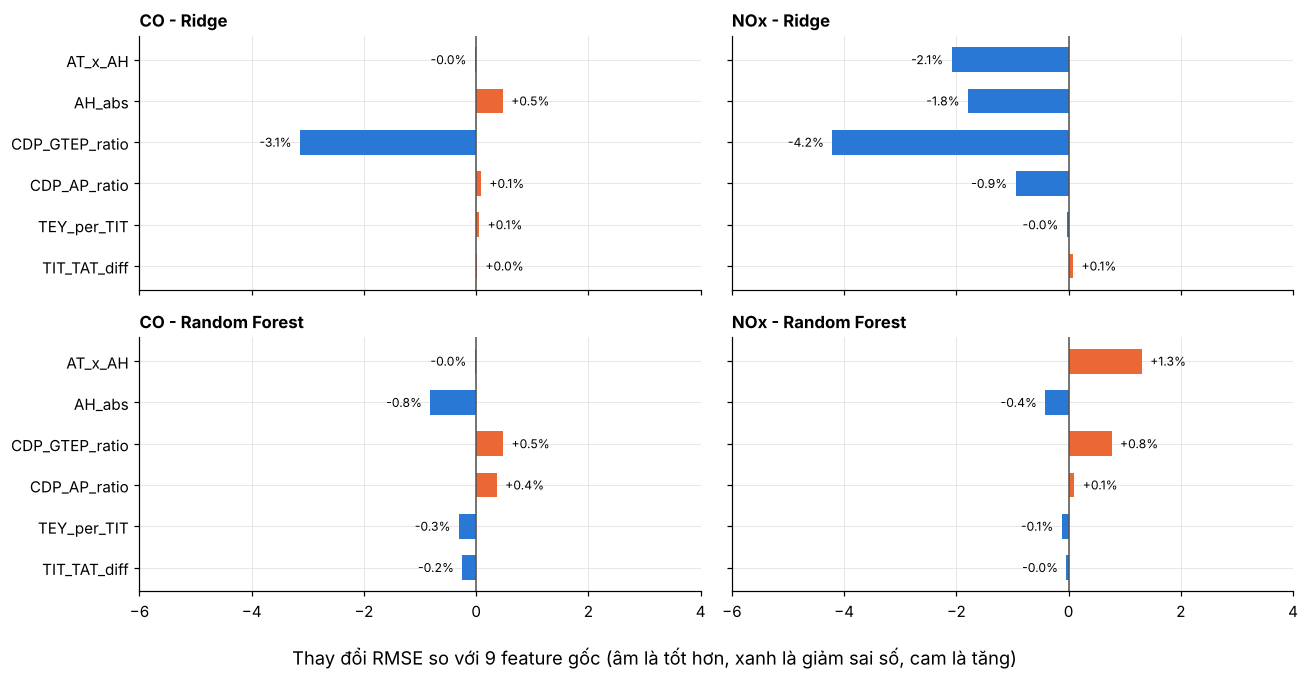

In [6]:
pct = (ablation / ablation.iloc[0] - 1) * 100
pct = pct.iloc[1:]

fig, axes = plt.subplots(2, 2, figsize=(12, 6.2), sharex=True, sharey=True)
for ax, col in zip(axes.T.flatten(), pct.columns):
    vals = pct[col]
    ax.barh(vals.index.str.replace('+ ', '', regex=False), vals.values,
            color=[BLUE if v < 0 else ORANGE for v in vals], height=0.6)
    ax.axvline(0, color='#52514e', lw=1)
    for i, v in enumerate(vals):
        ax.text(v + (0.15 if v >= 0 else -0.15), i, f'{v:+.1f}%', va='center',
                ha='left' if v >= 0 else 'right', fontsize=8)
    ax.set_title(f'{col[0]} - {col[1]}')
    ax.invert_yaxis()
axes[0, 0].set_xlim(-6, 4)
fig.supxlabel('Thay đổi RMSE so với 9 feature gốc (âm là tốt hơn, xanh là giảm sai số, cam là tăng)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fe_02_ablation.png', dpi=200, bbox_inches='tight')
plt.show()

In [7]:
gain = -pct
decision = pd.DataFrame({
    'Cặp giảm RMSE từ 0.5%': (gain >= 0.5).sum(axis=1),
    'Cặp xấu đi quá 1%': (gain < -1.0).sum(axis=1),
})
decision['Giữ lại'] = (decision.iloc[:, 0] >= 2) & (decision.iloc[:, 1] == 0)
decision.index = decision.index.str.replace('+ ', '', regex=False)
selected = list(decision.index[decision['Giữ lại']])

assert sorted(selected) == sorted(ENGINEERED_FEATURES)
print('Đặc trưng được giữ:', selected)
decision

Đặc trưng được giữ: ['CDP_GTEP_ratio', 'AH_abs']


,Cặp giảm RMSE từ 0.5%,Cặp xấu đi quá 1%,Giữ lại
TIT_TAT_diff,0,0,False
TEY_per_TIT,0,0,False
CDP_AP_ratio,1,0,False
CDP_GTEP_ratio,2,0,True
AH_abs,2,0,True
AT_x_AH,1,1,False


**Nhận xét.**

- `CDP_GTEP_ratio` giảm RMSE của Ridge 3.2% với CO và 4.2% với NOx; với Random Forest, RMSE tăng 0.5% và 0.8%, nằm trong ngưỡng cho phép.
- `AH_abs` giảm RMSE của Ridge với NOx 1.8% và của Random Forest với CO 0.7%.
- `AT_x_AH` giảm RMSE của Ridge với NOx 2.1% nhưng làm Random Forest tăng 1.3% nên bị loại.
- Ba ứng viên còn lại không tạo khác biệt đáng kể. `TIT_TAT_diff` là tổ hợp tuyến tính của hai cột sẵn có nên không bổ sung thông tin cho mô hình tuyến tính.

Đặc trưng mới có tác dụng rõ với mô hình tuyến tính, trong khi Random Forest gần như không thay đổi vì tự học được quan hệ phi tuyến và tương tác giữa các đặc trưng.

## 5. Lựa chọn tập đặc trưng

Ba tập đặc trưng được so sánh:

- `FS_BASE`: 9 đặc trưng gốc.
- `FS_COMPACT`: loại tuần tự đặc trưng có VIF lớn nhất cho đến khi mọi VIF không vượt quá 10.
- `FS_ENGINEERED`: 9 đặc trưng gốc cùng `CDP_GTEP_ratio` và `AH_abs`.

In [8]:
compact, dropped = prune_by_vif(train[BASE_FEATURES], threshold=10)
assert compact == FS_COMPACT

print('Thứ tự bị loại:')
print(pd.DataFrame(dropped, columns=['Feature', 'VIF lúc bị loại']).round(1).to_string(index=False))
print('\nGiữ lại:', compact)
print('\nVIF sau khi loại:')
print(compute_vif(train[compact]).round(2).to_string())

Thứ tự bị loại:
Feature  VIF lúc bị loại
    TEY            442.5
    CDP            342.8
   GTEP            256.4

Giữ lại: ['AT', 'AP', 'AH', 'AFDP', 'TIT', 'TAT']

VIF sau khi loại:


AT      2.13
AP      1.22
AH      1.67
AFDP    1.95
TIT     1.69
TAT     1.69


Quá trình loại theo VIF bỏ lần lượt TEY, CDP và GTEP; sáu đặc trưng còn lại có VIF không quá 2.2. Ba tập được đánh giá bằng phương pháp ở mục 4, bổ sung Linear Regression không chính quy hoá vì đây là mô hình chịu ảnh hưởng trực tiếp của đa cộng tuyến.

RMSE trung bình qua 2 fold theo thời gian:


CO                         NOx                     
              Linear  Ridge Random Forest Linear  Ridge Random Forest
FS_BASE        1.361  1.359         1.212  9.130  9.103         6.480
FS_COMPACT     1.350  1.350         1.218  9.035  9.034         6.451
FS_ENGINEERED  1.319  1.320         1.214  8.539  8.515         6.491

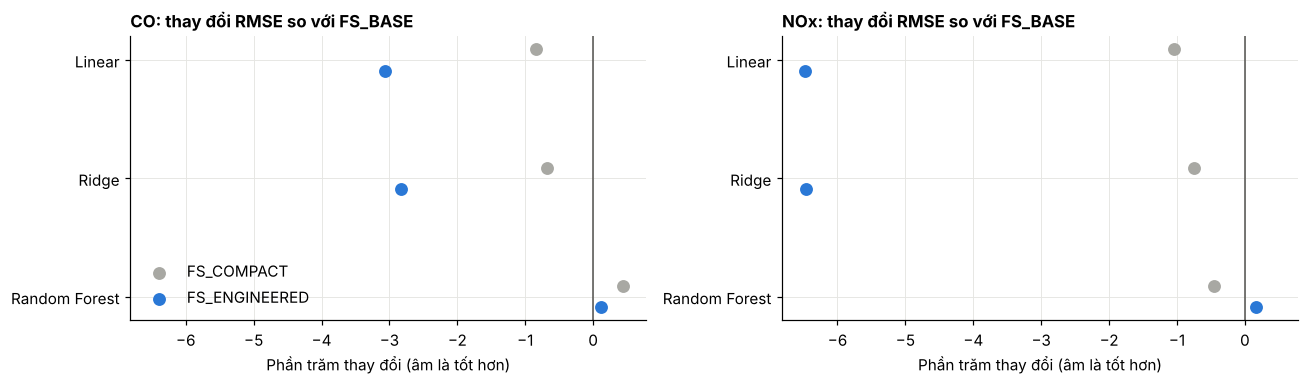

In [9]:
MODELS3 = {'Linear': LinearRegression(), 'Ridge': ridge, 'Random Forest': forest}
feature_sets = {'FS_BASE': FS_BASE, 'FS_COMPACT': FS_COMPACT, 'FS_ENGINEERED': FS_ENGINEERED}

set_scores = pd.DataFrame({name: score_set(cols, MODELS3) for name, cols in feature_sets.items()}).T
set_scores.columns = pd.MultiIndex.from_tuples(set_scores.columns)
set_pct = (set_scores / set_scores.loc['FS_BASE'] - 1) * 100

print('RMSE trung bình qua 2 fold theo thời gian:')
display(set_scores.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
palette = {'FS_COMPACT': GRAY, 'FS_ENGINEERED': BLUE}
for ax, target in zip(axes, ['CO', 'NOx']):
    for k, (name, color) in enumerate(palette.items()):
        vals = set_pct.loc[name, target]
        ax.scatter(vals.values, np.arange(len(vals)) + (k - 0.5) * 0.18, s=55, color=color, label=name, zorder=3)
    ax.axvline(0, color='#52514e', lw=1)
    ax.set_yticks(range(3))
    ax.set_yticklabels(set_pct.loc['FS_BASE', target].index)
    ax.invert_yaxis()
    ax.set_title(f'{target}: thay đổi RMSE so với FS_BASE')
    ax.set_xlabel('Phần trăm thay đổi (âm là tốt hơn)')
axes[0].legend(frameon=False, loc='lower left')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fe_03_feature_sets.png', dpi=200, bbox_inches='tight')
plt.show()

**Nhận xét.**

- `FS_COMPACT` không làm giảm độ chính xác dù chỉ còn 6 đặc trưng: RMSE của mô hình tuyến tính giảm khoảng 1%, Random Forest gần như không đổi. TEY, CDP và GTEP do đó là dư thừa.
- `FS_ENGINEERED` cho kết quả tốt nhất với mô hình tuyến tính, RMSE giảm khoảng 3% với CO và 6.5% với NOx so với `FS_BASE`. Với Random Forest, chênh lệch dưới 0.5%.
- Linear Regression và Ridge cho kết quả gần như trùng nhau: đa cộng tuyến ở mức này ảnh hưởng đến độ ổn định của hệ số nhiều hơn là độ chính xác dự đoán.

### 5.1. Độ ổn định của hệ số hồi quy

Linear Regression trên đặc trưng đã chuẩn hoá được huấn luyện riêng cho từng năm 2011, 2012 và 2013. Một mô hình phù hợp để diễn giải cần cho hệ số tương tự nhau giữa các năm, ít nhất là cùng dấu. Mỗi hệ số biểu thị mức thay đổi của target (mg/m³) khi đặc trưng tăng một độ lệch chuẩn và các đặc trưng khác giữ nguyên.

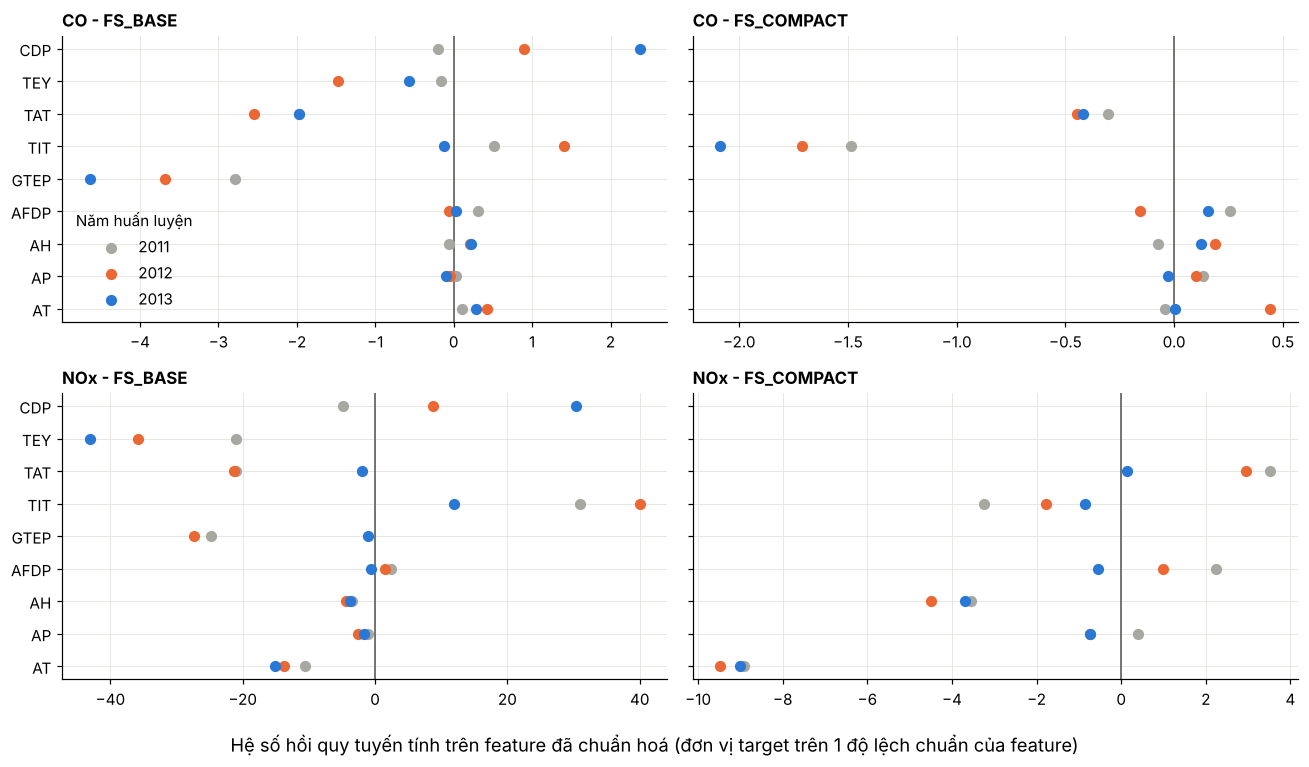

Tập            FS_BASE               FS_COMPACT            
Năm               2011   2012   2013       2011  2012  2013
Target Feature                                             
CO     CDP       -0.20   0.89   2.37        NaN   NaN   NaN
       TEY       -0.16  -1.48  -0.57        NaN   NaN   NaN
       TIT        0.52   1.41  -0.12      -1.49 -1.71 -2.09
NOx    CDP       -4.82   8.75  30.33        NaN   NaN   NaN
       TEY      -21.02 -35.80 -43.15        NaN   NaN   NaN
       TIT       30.96  40.02  11.87      -3.24 -1.78 -0.86

In [10]:
coef_rows = []
for set_name, cols in [('FS_BASE', FS_BASE), ('FS_COMPACT', FS_COMPACT)]:
    for t in TARGETS:
        for year in YEARS:
            part = train[train['year'] == year]
            lr = make_pipeline(StandardScaler(), LinearRegression()).fit(part[cols], part[t])
            coef_rows += [{'Tập': set_name, 'Target': LABEL[t], 'Năm': year, 'Feature': c, 'Hệ số': v}
                          for c, v in zip(cols, lr[-1].coef_)]
coefs = pd.DataFrame(coef_rows)

year_colors = dict(zip(YEARS, [GRAY, ORANGE, BLUE]))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey='row')
for row, target in enumerate(['CO', 'NOx']):
    for col, set_name in enumerate(['FS_BASE', 'FS_COMPACT']):
        ax = axes[row, col]
        sub = coefs[(coefs['Target'] == target) & (coefs['Tập'] == set_name)]
        order = {f: i for i, f in enumerate(FS_BASE)}
        for year in YEARS:
            pts = sub[sub['Năm'] == year]
            ax.scatter(pts['Hệ số'], pts['Feature'].map(order), s=40, color=year_colors[year], label=str(year), zorder=3)
        ax.axvline(0, color='#52514e', lw=1)
        ax.set_yticks(range(len(FS_BASE)))
        ax.set_yticklabels(FS_BASE)
        ax.invert_yaxis()
        ax.set_title(f'{target} - {set_name}')
axes[0, 0].legend(title='Năm huấn luyện', frameon=False, loc='lower left')
fig.supxlabel('Hệ số hồi quy tuyến tính trên feature đã chuẩn hoá (đơn vị target trên 1 độ lệch chuẩn của feature)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fe_04_coefficient_stability.png', dpi=200, bbox_inches='tight')
plt.show()

coefs[coefs['Feature'].isin(['TIT', 'TEY', 'CDP'])].pivot_table(
    index=['Target', 'Feature'], columns=['Tập', 'Năm'], values='Hệ số').round(2)

**Nhận xét.**

- Với `FS_BASE`, hệ số biến động mạnh và đổi dấu giữa các năm. Hệ số của TIT với CO lần lượt là +0.52, +1.41 và −0.12, trái chiều với tương quan −0.73; hệ số của CDP với NOx tăng từ −4.8 lên +30.3.
- Với `FS_COMPACT`, hệ số của TIT với CO luôn âm (−1.49, −1.71, −2.09) và hệ số của AT với NOx ổn định quanh −9.
- Một số hệ số NOx trong `FS_COMPACT` vẫn thay đổi theo năm (TAT từ +3.5 xuống +0.1) dù mọi VIF đều dưới 2.2, phù hợp với sự thay đổi quan hệ theo thời gian được phân tích ở mục 10.

**Đề xuất sử dụng.** `FS_ENGINEERED` cho mô hình tuyến tính khi mục tiêu là độ chính xác; `FS_BASE` cho mô hình cây; `FS_COMPACT` khi cần diễn giải hệ số của mô hình tuyến tính.

## 6. Mức độ quan trọng của đặc trưng

Mức độ quan trọng được đo bằng permutation importance, là mức tăng RMSE khi xáo trộn ngẫu nhiên giá trị của một đặc trưng trên dữ liệu không dùng để huấn luyện. Random Forest được huấn luyện trên 2011–2012 với `FS_ENGINEERED` và đánh giá trên 2013. Tương quan Spearman với target được trình bày bên cạnh để thể hiện chiều ảnh hưởng.

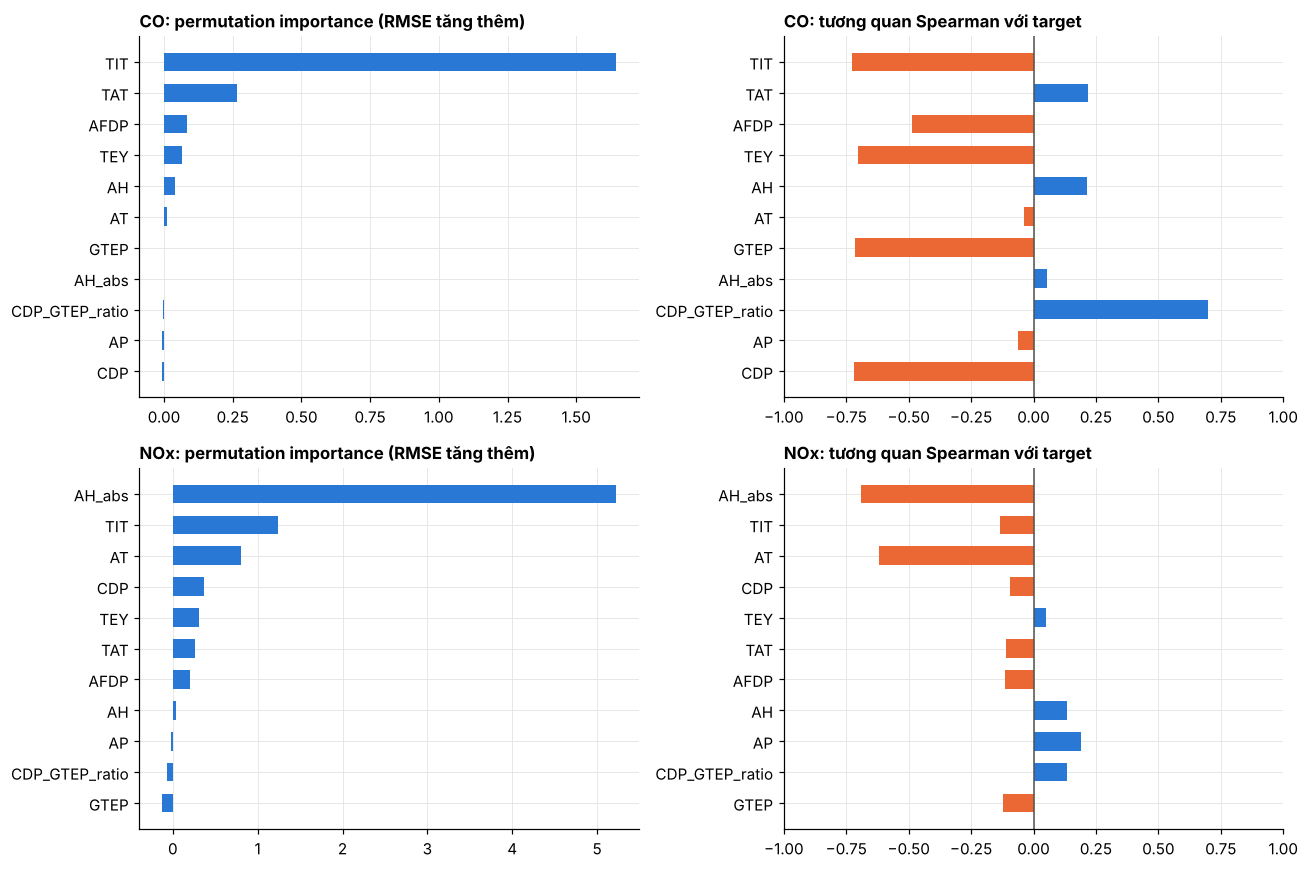

In [11]:
fit_df = train_fe[train_fe['year'] <= 2012]
val_df = train_fe[train_fe['year'] == 2013]
rf_eval = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=0)

eval_models, perm = {}, {}
for t in TARGETS:
    eval_models[t] = clone(rf_eval).fit(fit_df[FS_ENGINEERED], fit_df[t])
    perm[t] = pd.Series(
        permutation_importance(eval_models[t], val_df[FS_ENGINEERED], val_df[t], n_repeats=5,
                               random_state=0, scoring='neg_root_mean_squared_error').importances_mean,
        index=FS_ENGINEERED).sort_values()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, t in enumerate(TARGETS):
    imp = perm[t]
    axes[row, 0].barh(imp.index, imp.values, color=BLUE, height=0.6)
    axes[row, 0].set_title(f'{LABEL[t]}: permutation importance (RMSE tăng thêm)')
    rho = train_fe[FS_ENGINEERED + [t]].corr(method='spearman')[t].drop(t).reindex(imp.index)
    axes[row, 1].barh(rho.index, rho.values, color=[BLUE if v >= 0 else ORANGE for v in rho], height=0.6)
    axes[row, 1].axvline(0, color='#52514e', lw=1)
    axes[row, 1].set_xlim(-1, 1)
    axes[row, 1].set_title(f'{LABEL[t]}: tương quan Spearman với target')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fe_05_importance.png', dpi=200, bbox_inches='tight')
plt.show()

Khi nhiều đặc trưng cùng mang một thông tin, xáo trộn riêng từng đặc trưng sẽ đánh giá thấp mức quan trọng thực sự, vì mô hình vẫn lấy được thông tin đó từ các đặc trưng còn lại. Bảng dưới so sánh tổng importance riêng lẻ với importance khi xáo trộn đồng thời cả khối GTEP, CDP, TEY và `CDP_GTEP_ratio`.

In [12]:
block = ['GTEP', 'CDP', 'TEY', 'CDP_GTEP_ratio']
rows = {}
for t in TARGETS:
    single = perm[t]
    joint = group_permutation_importance(eval_models[t], val_df[FS_ENGINEERED], val_df[t], {'block': block})['block']
    rows[LABEL[t]] = {**{c: single[c] for c in block}, 'Tổng các giá trị riêng lẻ': single[block].sum(),
                      'Xáo trộn cả khối cùng lúc': joint}
pd.DataFrame(rows).round(3)

,CO,NOx
GTEP,0.001,-0.126
CDP,-0.007,0.362
TEY,0.065,0.303
CDP_GTEP_ratio,-0.004,-0.071
Tổng các giá trị riêng lẻ,0.054,0.469
Xáo trộn cả khối cùng lúc,0.059,1.373


**Nhận xét.**

- Với CO, TIT chiếm ưu thế rõ rệt: RMSE tăng 1.65 khi xáo trộn TIT, so với độ lệch chuẩn 1.97 của CO. Tiếp theo là TAT (0.26), các đặc trưng còn lại không đáng kể.
- Với NOx, `AH_abs` quan trọng nhất (5.2), tiếp theo là TIT (1.2) và AT (0.8), trong khi AH gốc chỉ đạt 0.03. Đặc trưng độ ẩm tuyệt đối thể hiện đúng lượng hơi nước mà độ ẩm tương đối không phản ánh được.
- Với NOx, xáo trộn đồng thời khối GTEP, CDP, TEY làm RMSE tăng 1.37, gấp khoảng 2.9 lần tổng importance riêng lẻ (0.47). Với CO, hai giá trị xấp xỉ nhau (0.054 và 0.059), tức khối này không mang thêm thông tin ngoài TIT. Do đó importance riêng lẻ gần 0 không có nghĩa là đặc trưng vô ích.
- GTEP, CDP và TEY có tương quan Spearman khoảng −0.7 với CO nhưng importance gần 0: tương quan cao không đồng nghĩa với đóng góp riêng vào dự đoán.

## 7. Diễn giải theo cơ sở vật lý

Giả thuyết: nhiệt độ khí vào tuabin (TIT) cao giúp nhiên liệu cháy hoàn toàn hơn nên CO giảm, đồng thời thúc đẩy hình thành NOx nhiệt theo cơ chế Zeldovich nên NOx tăng. Giả thuyết được kiểm tra bằng partial dependence, tức giá trị dự đoán trung bình của Random Forest (huấn luyện trên toàn bộ tập huấn luyện) khi một đặc trưng thay đổi và các đặc trưng khác giữ nguyên như trong dữ liệu.

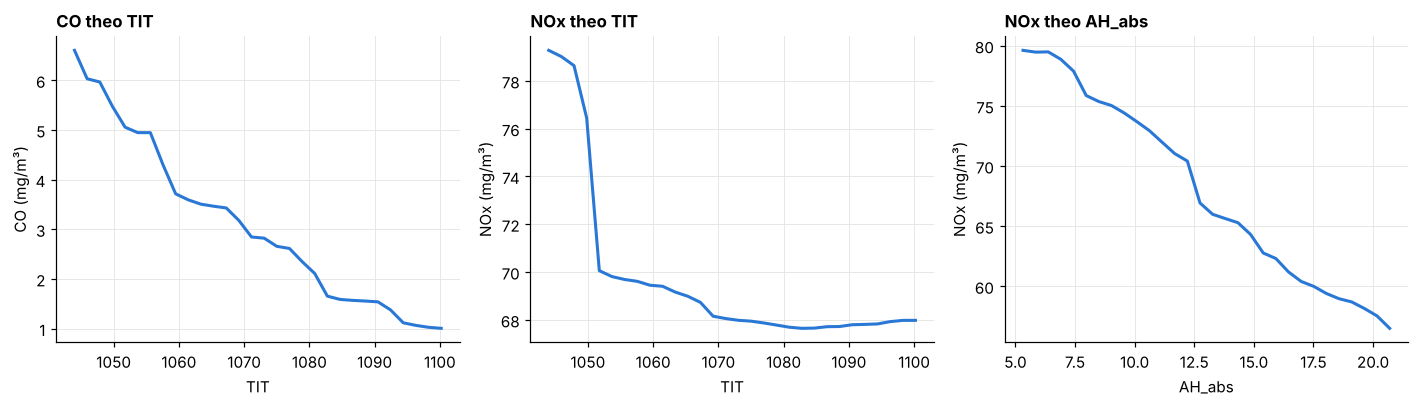

In [13]:
final_models = {t: clone(rf_eval).fit(train_fe[FS_ENGINEERED], train_fe[t]) for t in TARGETS}

panels = [('TIT', 'CO_clipped', 'CO (mg/m³)'), ('TIT', 'NOX', 'NOx (mg/m³)'), ('AH_abs', 'NOX', 'NOx (mg/m³)')]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (feat, t, ylabel) in zip(axes, panels):
    pdp = partial_dependence(final_models[t], train_fe[FS_ENGINEERED], [feat],
                             grid_resolution=30, percentiles=(0.02, 0.98))
    ax.plot(pdp['grid_values'][0], pdp['average'][0], color=BLUE, lw=2)
    ax.set_xlabel(feat)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{LABEL[t]} theo {feat}')
plt.tight_layout()
plt.savefig(FIG_DIR / 'fe_06_partial_dependence.png', dpi=200, bbox_inches='tight')
plt.show()

TIT tương quan khoảng 0.9 với tải (TEY). Để tách ảnh hưởng của nhiệt độ khỏi ảnh hưởng của tải, dữ liệu được chia thành 5 nhóm theo phân vị của TEY và tính tương quan giữa TIT với từng target trong mỗi nhóm.

In [14]:
load_group = pd.qcut(train_fe['TEY'], 5, labels=['Q1 (tải thấp)', 'Q2', 'Q3', 'Q4', 'Q5 (tải cao)'])
rows = []
for name, g in train_fe.groupby(load_group, observed=True):
    rows.append({'Nhóm tải': name, 'TEY trung bình': g['TEY'].mean(),
                 'Spearman TIT-CO': g['TIT'].corr(g['CO_clipped'], method='spearman'),
                 'Spearman TIT-NOx': g['TIT'].corr(g['NOX'], method='spearman')})
pd.DataFrame(rows).round(2).set_index('Nhóm tải')

,TEY trung bình,Spearman TIT-CO,Spearman TIT-NOx
Nhóm tải,,,
Q1 (tải thấp),110.04,-0.71,-0.80
Q2,128.45,-0.61,-0.21
Q3,133.79,-0.18,-0.62
Q4,137.39,-0.38,-0.62
Q5 (tải cao),158.07,-0.06,-0.08


**Nhận xét.**

- CO phù hợp với giả thuyết: CO dự đoán giảm từ khoảng 6.6 xuống 1.0 mg/m³ khi TIT tăng từ 1044 lên 1100 °C, và tương quan TIT–CO âm trong cả 5 nhóm tải (từ −0.71 đến −0.06).
- NOx không phù hợp với vế thứ hai của giả thuyết: NOx dự đoán giảm từ khoảng 79 xuống 70 mg/m³ khi TIT tăng từ 1044 lên 1056 °C rồi gần như không đổi quanh 68 mg/m³, và tương quan TIT–NOx âm trong cả 5 nhóm tải. Các nguyên nhân khả dĩ, chưa được kiểm chứng, gồm: vùng TIT thấp ứng với chế độ vận hành non tải có đặc tính cháy khác, khoảng TIT trong dữ liệu hẹp, và ảnh hưởng lấn át của điều kiện môi trường.
- Độ ẩm có ảnh hưởng rõ đến NOx: NOx dự đoán giảm từ khoảng 80 xuống 56 mg/m³ khi `AH_abs` tăng từ 5 lên 21 g/m³. Kết quả phù hợp với vai trò hấp thụ nhiệt của hơi nước, làm giảm nhiệt độ ngọn lửa và hạn chế NOx nhiệt. AT có tương quan 0.9 với `AH_abs`, điều này giải thích tương quan âm giữa AT và NOx (−0.62).

Partial dependence giả định một đặc trưng có thể thay đổi độc lập với các đặc trưng khác, trong khi TIT và TEY liên hệ chặt chẽ, nên kết quả chỉ thể hiện xu hướng mô hình học được, không phải quan hệ nhân quả.

## 8. Dịch chuyển phân phối theo thời gian

Biểu đồ dưới thể hiện trung bình của mỗi đặc trưng theo năm so với giai đoạn huấn luyện, tính theo đơn vị độ lệch chuẩn. Phân tích chỉ sử dụng giá trị đặc trưng, không sử dụng nhãn của tập kiểm tra.

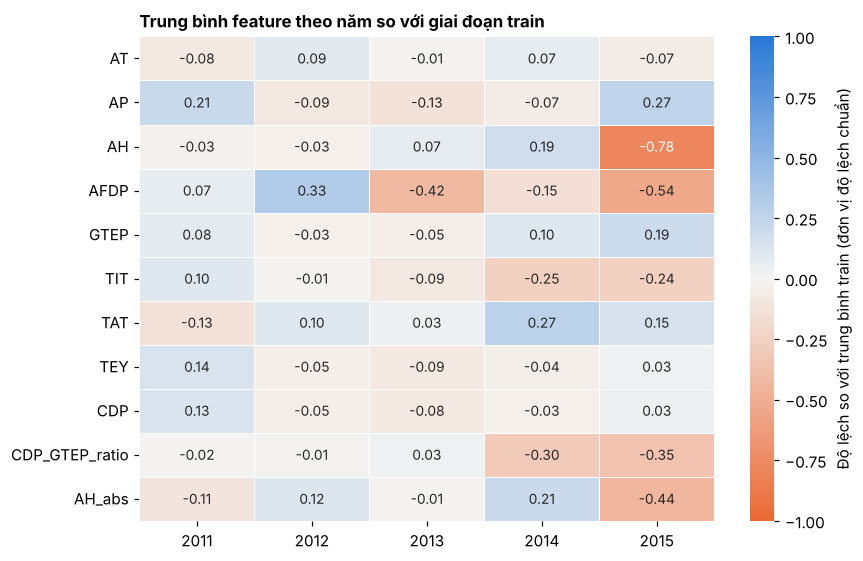

In [15]:
all_fe = add_physical_features(df)
ref = all_fe[all_fe['year'] <= 2013][FS_ENGINEERED]
shift = all_fe.groupby('year')[FS_ENGINEERED].mean().sub(ref.mean()).div(ref.std()).T

plt.figure(figsize=(8, 5.2))
sns.heatmap(shift, cmap=DIVERGING, center=0, vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 9}, linewidths=0.5, cbar_kws={'label': 'Độ lệch so với trung bình train (đơn vị độ lệch chuẩn)'})
plt.title('Trung bình feature theo năm so với giai đoạn train', loc='left', fontweight='bold')
plt.xlabel('')
plt.gca().grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR / 'fe_07_year_shift.png', dpi=200, bbox_inches='tight')
plt.show()

**Nhận xét.** Phân phối đặc trưng thay đổi ở giai đoạn kiểm tra (covariate shift). Năm 2015, AH thấp hơn 0.78, AFDP thấp hơn 0.54 và `AH_abs` thấp hơn 0.44 độ lệch chuẩn so với giai đoạn huấn luyện; `CDP_GTEP_ratio` lệch khoảng 0.3 ở cả hai năm. Các đặc trưng chính của CO (TIT, TAT) lệch không quá 0.27. Do NOx phụ thuộc nhiều nhất vào `AH_abs`, sai số NOx trên tập kiểm tra được dự kiến cao hơn sai số kiểm định chéo. Kết quả này chỉ dùng để chẩn đoán, không dùng để lựa chọn đặc trưng.

## 9. Chuẩn hoá dữ liệu

Mô hình tuyến tính cần các đặc trưng có cùng thang đo; mô hình cây không cần vì chỉ so sánh giá trị với ngưỡng. `StandardScaler` được fit trên tập huấn luyện rồi dùng để biến đổi tập kiểm tra (hàm `scale_features`), tránh để thống kê của tập kiểm tra ảnh hưởng đến quá trình huấn luyện.

In [16]:
X_train = add_physical_features(train)[FS_ENGINEERED]
X_test = add_physical_features(test)[FS_ENGINEERED]
scaler, X_train_s, X_test_s = scale_features(X_train, X_test)

check = pd.DataFrame({'Train: trung bình': X_train_s.mean(), 'Train: độ lệch chuẩn': X_train_s.std(),
                      'Test: trung bình': X_test_s.mean(), 'Test: độ lệch chuẩn': X_test_s.std()})
check.round(2)

,Train: trung bình,Train: độ lệch chuẩn,Test: trung bình,Test: độ lệch chuẩn
AT,-0.0,1.0,-0.00,1.03
AP,-0.0,1.0,0.10,1.02
AH,-0.0,1.0,-0.31,1.07
AFDP,0.0,1.0,-0.35,0.84
GTEP,-0.0,1.0,0.15,0.97
TIT,-0.0,1.0,-0.25,1.08
TAT,-0.0,1.0,0.21,0.66
TEY,-0.0,1.0,-0.00,0.93
CDP,0.0,1.0,0.00,0.94
CDP_GTEP_ratio,-0.0,1.0,-0.32,1.04


**Nhận xét.** Sau chuẩn hoá, tập huấn luyện có trung bình 0 và độ lệch chuẩn 1. Tập kiểm tra lệch khỏi các giá trị này (trung bình của AH là −0.31, của AFDP là −0.35, độ lệch chuẩn của TAT là 0.66), phản ánh dịch chuyển phân phối ở mục 8.

## 10. Phân tích sai số trên tập kiểm tra

Mô hình XGBoost sau khi tối ưu siêu tham số đạt R² khoảng 0.66 với CO nhưng R² âm với NOx trên tập kiểm tra, tức kém hơn việc luôn dự đoán bằng giá trị trung bình. Mục này đánh giá ảnh hưởng của tập đặc trưng lên kết quả kiểm tra và xác định nguyên nhân sai số NOx, sử dụng bộ siêu tham số tốt nhất từ quá trình tối ưu. Các tập đặc trưng đã được chọn ở mục 5 và không thay đổi theo kết quả của mục này.

Target CO trên tập kiểm tra là `CO_clipped`, do đó sai số CO thấp hơn so với khi đánh giá trên CO gốc.

In [17]:
import xgboost
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

print('xgboost', xgboost.__version__)

XGB_PARAMS = {
    'CO_clipped': dict(n_estimators=300, max_depth=5, learning_rate=0.01, subsample=0.7, colsample_bytree=1.0),
    'NOX': dict(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8),
}
data = add_physical_features(df).reset_index(drop=True)
is_train = data['year'] <= 2013

rows = []
for t in TARGETS:
    for name, cols in feature_sets.items():
        model = XGBRegressor(random_state=42, **XGB_PARAMS[t]).fit(data.loc[is_train, cols], data.loc[is_train, t])
        pred = model.predict(data.loc[~is_train, cols])
        y = data.loc[~is_train, t]
        rows.append({'Target': LABEL[t], 'Tập feature': name,
                     'RMSE test': np.sqrt(mean_squared_error(y, pred)), 'R² test': r2_score(y, pred)})
pd.DataFrame(rows).set_index(['Target', 'Tập feature']).round(3)

xgboost 3.4.1


RMSE test  R² test
Target Tập feature                      
CO     FS_BASE            1.063    0.659
       FS_COMPACT         1.075    0.652
       FS_ENGINEERED      1.055    0.664
NOx    FS_BASE           12.585   -0.416
       FS_COMPACT        12.643   -0.429
       FS_ENGINEERED     12.496   -0.396

**Nhận xét.** Với CO, R² của ba tập đặc trưng chênh nhau khoảng 0.01. Với NOx, cả ba tập đều có R² âm và chênh lệch không đáng kể. Tập đặc trưng không phải nguyên nhân chính của sai số NOx.

Để xác định nguyên nhân, phần dư (giá trị thực tế trừ giá trị dự đoán) của mô hình huấn luyện trên 2011–2013 được tính trung bình theo 12 đoạn liên tiếp trong mỗi năm.

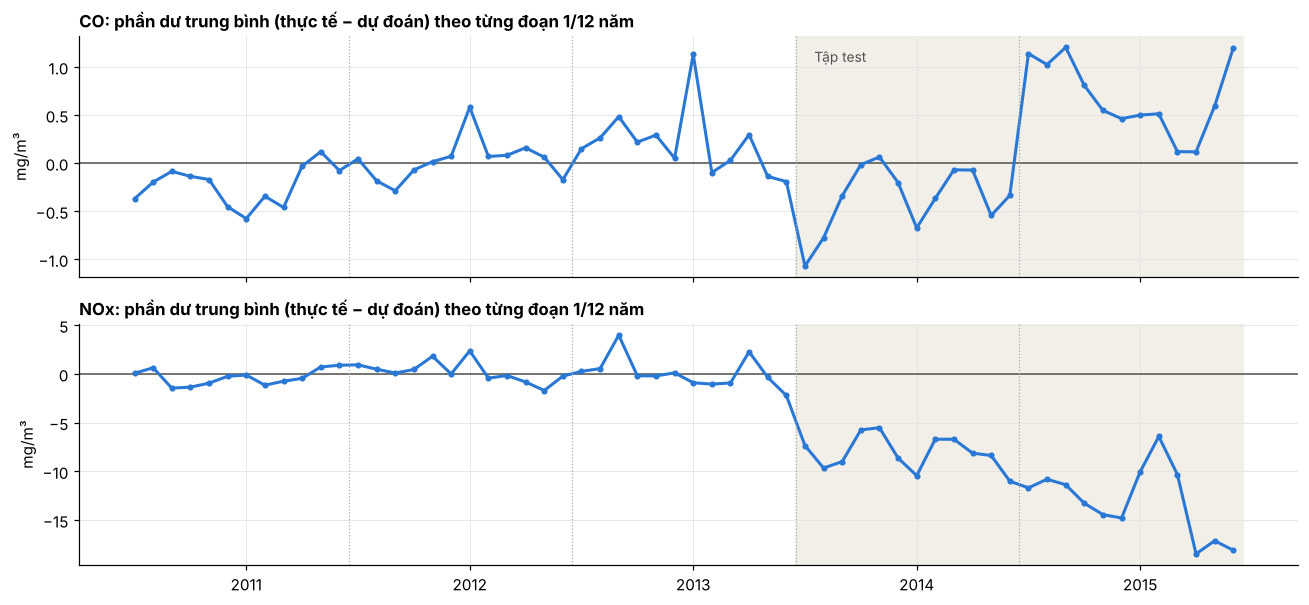

,NOx thực tế (TB),NOx dự đoán (TB),Phần dư NOx (TB),Phần dư CO (TB),Spearman NOx với AH_abs
year,,,,,
2011,67.58,67.919998,-0.35,-0.23,-0.74
2012,68.79,68.550003,0.23,0.03,-0.68
2013,70.01,69.889999,0.11,0.21,-0.68
2014,60.08,68.180000,-8.10,-0.37,-0.80
2015,59.89,72.959999,-13.07,0.69,-0.68


In [18]:
for t in TARGETS:
    model = XGBRegressor(random_state=42, **XGB_PARAMS[t]).fit(data.loc[is_train, FS_BASE], data.loc[is_train, t])
    data[f'pred_{t}'] = model.predict(data[FS_BASE])
    data[f'resid_{t}'] = data[t] - data[f'pred_{t}']

data['chunk'] = (data.groupby('year').cumcount() / data.groupby('year')['year'].transform('size') * 12).astype(int)
chunks = data.groupby(['year', 'chunk'])[[f'resid_{t}' for t in TARGETS]].mean().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(12, 5.6), sharex=True)
x = np.arange(len(chunks))
for ax, t in zip(axes, TARGETS):
    ax.axvspan(35.5, len(chunks) - 0.5, color='#f1efe8', zorder=0)
    ax.axhline(0, color='#52514e', lw=1)
    ax.plot(x, chunks[f'resid_{t}'], color=BLUE, lw=2, marker='o', ms=3)
    for b in range(12, len(chunks), 12):
        ax.axvline(b - 0.5, color=GRAY, lw=0.8, ls=':')
    ax.set_ylabel('mg/m³')
    ax.set_title(f'{LABEL[t]}: phần dư trung bình (thực tế − dự đoán) theo từng đoạn 1/12 năm')
axes[0].text(36.5, axes[0].get_ylim()[1] * 0.8, 'Tập test', color='#52514e', fontsize=9)
axes[1].set_xticks(np.arange(6, len(chunks), 12))
axes[1].set_xticklabels(sorted(data['year'].unique()))
plt.tight_layout()
plt.savefig(FIG_DIR / 'fe_08_nox_residual_drift.png', dpi=200, bbox_inches='tight')
plt.show()

yearly = data.groupby('year').agg(**{
    'NOx thực tế (TB)': ('NOX', 'mean'), 'NOx dự đoán (TB)': ('pred_NOX', 'mean'),
    'Phần dư NOx (TB)': ('resid_NOX', 'mean'), 'Phần dư CO (TB)': ('resid_CO_clipped', 'mean'),
    'Spearman NOx với AH_abs': ('NOX', lambda s: s.corr(data.loc[s.index, 'AH_abs'], method='spearman')),
})
yearly.round(2)

In [19]:
test_part = data[~is_train]
shift_removed = test_part['pred_NOX'] + test_part.groupby('year')['resid_NOX'].transform('mean')
print(f"R² NOx trên test, model gốc                          : {r2_score(test_part['NOX'], test_part['pred_NOX']):.3f}")
print(f"R² NOx trên test, sau khi bù lệch trung bình mỗi năm : {r2_score(test_part['NOX'], shift_removed):.3f}")

grow = data['year'] <= 2014
last = data['year'] == 2015
for t in TARGETS:
    model = XGBRegressor(random_state=42, **XGB_PARAMS[t]).fit(data.loc[grow, FS_BASE], data.loc[grow, t])
    pred = model.predict(data.loc[last, FS_BASE])
    print(f"Huấn luyện 2011 đến 2014, kiểm tra 2015, {LABEL[t]:>3}: R² = {r2_score(data.loc[last, t], pred):.3f}, "
          f"dự đoán lệch trung bình {np.mean(pred - data.loc[last, t]):+.2f} mg/m³")

R² NOx trên test, model gốc                          : -0.416
R² NOx trên test, sau khi bù lệch trung bình mỗi năm : 0.649


Huấn luyện 2011 đến 2014, kiểm tra 2015,  CO: R² = 0.528, dự đoán lệch trung bình -0.91 mg/m³


Huấn luyện 2011 đến 2014, kiểm tra 2015, NOx: R² = 0.020, dự đoán lệch trung bình +8.36 mg/m³


**Nhận xét.** Trong 2011–2013, phần dư NOx trung bình mỗi năm gần 0 (dưới 0.4 mg/m³). Từ đoạn đầu tiên của năm 2014, phần dư giảm đột ngột xuống khoảng −7 mg/m³, dao động từ −5 đến −11 trong năm 2014 và từ −6 đến −19 trong năm 2015. Với cùng giá trị cảm biến, NOx thực tế từ năm 2014 thấp hơn trước khoảng 8 đến 13 mg/m³, trong khi phần dư của CO không có bước nhảy tương tự.

Đây là hiện tượng concept drift: quan hệ giữa đặc trưng và target thay đổi theo thời gian, khác với covariate shift ở mục 8 vốn chỉ là thay đổi phân phối của đặc trưng. Các bằng chứng:

- Thay đổi xảy ra đột ngột tại ranh giới năm, không tăng dần.
- Khi bù độ lệch trung bình của từng năm, R² NOx trên tập kiểm tra tăng từ khoảng −0.4 lên khoảng 0.65: mô hình vẫn nắm được biến thiên trong năm và chỉ sai ở mức nền. Phép bù này sử dụng nhãn của tập kiểm tra nên chỉ có ý nghĩa chẩn đoán.
- Tương quan giữa NOx và `AH_abs` ổn định qua cả 5 năm (từ −0.68 đến −0.80).
- Bổ sung năm 2014 vào tập huấn luyện vẫn cho dự đoán năm 2015 lệch khoảng +8 mg/m³.

Nguyên nhân có thể là một thay đổi trong hệ thống mà 9 cảm biến không ghi nhận, như bảo trì hoặc hiệu chỉnh buồng đốt, thay đổi chế độ kiểm soát khí thải hoặc hiệu chuẩn lại thiết bị đo; dữ liệu hiện có không đủ để kiểm chứng. Năm 2015 khô hơn nên mô hình, vốn học rằng không khí khô làm NOx tăng, dự đoán NOx càng cao, khiến độ lệch năm 2015 lớn hơn năm 2014.

## 11. Kết luận

| Tập đặc trưng | Số đặc trưng | Thành phần | Sử dụng |
|---|---|---|---|
| `FS_BASE` | 9 | AT, AP, AH, AFDP, GTEP, TIT, TAT, TEY, CDP | Mô hình cây (Random Forest, XGBoost) |
| `FS_COMPACT` | 6 | AT, AP, AH, AFDP, TIT, TAT | Mô hình tuyến tính khi cần diễn giải hệ số |
| `FS_ENGINEERED` | 11 | `FS_BASE` + `CDP_GTEP_ratio`, `AH_abs` | Mô hình tuyến tính (Linear, Ridge), kết hợp chuẩn hoá |

- Đa cộng tuyến nghiêm trọng đến từ khối TEY, CDP, GTEP. Loại bỏ khối này không làm giảm độ chính xác và giúp hệ số của mô hình tuyến tính ổn định, đúng chiều vật lý.
- `AH_abs` và `CDP_GTEP_ratio` cải thiện mô hình tuyến tính (RMSE giảm khoảng 3% với CO và 6.5% với NOx); mô hình cây gần như không thay đổi.
- CO giảm khi TIT tăng, phù hợp với cơ chế cháy hoàn toàn. NOx phụ thuộc chủ yếu vào độ ẩm tuyệt đối và không tăng theo TIT như giả thuyết ban đầu.
- NOx chịu concept drift từ năm 2014: với cùng điều kiện cảm biến, NOx thực tế thấp hơn khoảng 8 đến 13 mg/m³. Đây là nguyên nhân chính khiến R² NOx trên tập kiểm tra âm.

**Hạn chế và hướng phát triển.** Kiểm định chéo chỉ có hai fold và siêu tham số được cố định khi so sánh, nên chênh lệch dưới 1% chưa đủ tin cậy. Để xử lý concept drift, mô hình NOx cần được cập nhật định kỳ bằng dữ liệu mới có nhãn hoặc tăng trọng số cho dữ liệu gần đây.